<a href="https://colab.research.google.com/github/Austin-Weight/Higher-Education/blob/main/Python_EDA_Project_using_%22Predict_Students'_Dropout_and_Academic_Success%22_and_%22College_Scorecard%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Python EDA Project using "Predict Students' Dropout and Academic Success" and "College Scorecard"
By Austin Weight

# Import libraries

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# "Predict Students' Dropout and Academic Success"

Import the file

In [45]:
pip install ucimlrepo

In [46]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
predict_students_dropout_and_academic_success = fetch_ucirepo(id=697)

# data (as pandas dataframes)
X = predict_students_dropout_and_academic_success.data.features
y = predict_students_dropout_and_academic_success.data.targets

# metadata
print(predict_students_dropout_and_academic_success.metadata)

# variable information
print(predict_students_dropout_and_academic_success.variables)


{'uci_id': 697, 'name': "Predict Students' Dropout and Academic Success", 'repository_url': 'https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success', 'data_url': 'https://archive.ics.uci.edu/static/public/697/data.csv', 'abstract': "A dataset created from a higher education institution (acquired from several disjoint databases) related to students enrolled in different undergraduate degrees, such as agronomy, design, education, nursing, journalism, management, social service, and technologies.\nThe dataset includes information known at the time of student enrollment (academic path, demographics, and social-economic factors) and the students' academic performance at the end of the first and second semesters. \nThe data is used to build classification models to predict students' dropout and academic sucess. The problem is formulated as a three category classification task, in which there is a strong imbalance towards one of the classes.", 'area': 'Social Sc

In [47]:
import pandas as pd

# Join X and y along columns
df1 = pd.concat([X, y], axis=1)

# Display the combined dataframe
df1

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate


In [48]:
df1.columns

Index(['Marital Status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd s

How much more likely are men to dropout than women?

In [49]:
gender_target = df1.groupby(['Gender', 'Target'])['Target'].count()

In [50]:
# 0 is female, 1 is male
gender_0_dropout_percentage = (gender_target.loc[(0, 'Dropout')]) / (gender_target.loc[(0, 'Dropout')] + gender_target.loc[(0, 'Graduate')]) * 100
gender_1_dropout_percentage = (gender_target.loc[(1, 'Dropout')]) / (gender_target.loc[(1, 'Dropout')] + gender_target.loc[(1, 'Graduate')]) * 100
gender_rate_difference = gender_1_dropout_percentage - gender_0_dropout_percentage
print("Assuming the dataset is a representative sample, men are", gender_rate_difference.round(2), "percent more likely to dropout than women.")

Assuming the dataset is a representative sample, men are 25.89 percent more likely to dropout than women.


# "College Scorecard"




Read CSV

In [51]:
df = pd.read_csv('Most-Recent-Cohorts-Institution_05192025.csv')

/tmp/ipykernel_1060/1166162716.py:1: DtypeWarning:

Columns (9,1407,1408,1431,1432,1532,1537,1538,1539,1540,1542,1546,1589,1601,1602,1606,1608,1611,1614,1615,1616,1619,1620,1621,1622,1623,1624,1625,1626,1627,1628,1629,1653,1679,1690,1692,1697,1700,1702,1725,1726,1727,1728,1729,1743,1815,1816,1817,1818,1823,1824,1830,1831,1879,1880,1881,1882,1883,1884,1885,1886,1887,1888,1889,1890,1891,1892,1893,1894,1895,1896,1897,1898,1909,1910,1911,1912,1913,1957,1958,1959,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,1970,1971,1972,1973,1974,1975,1976,1983,1984,2376,2377,2403,2404,2495,2496,2497,2498,2499,2500,2501,2502,2503,2504,2505,2506,2507,2508,2509,2510,2511,2512,2513,2514,2515,2516,2517,2518,2519,2520,2521,2522,2523,2524,2525,2526,2527,2528,2529,2530,2958,3215,3231,3235,3236) have mixed types. Specify dtype option on import or set low_memory=False.



Get the basics

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6429 entries, 0 to 6428
Columns: 3306 entries, UNITID to SCORECARD_SECTOR
dtypes: float64(920), int64(14), object(2372)
memory usage: 162.2+ MB


In [53]:
df.shape

(6429, 3306)

The CSV file came with thousands of columns

In [54]:
df.head()

,UNITID,OPEID,OPEID6,INSTNM,CITY,STABBR,ZIP,ACCREDAGENCY,INSTURL,NPCURL,...,COUNT_WNE_MALE1_P11,GT_THRESHOLD_P11,MD_EARN_WNE_INC1_P11,MD_EARN_WNE_INC2_P11,MD_EARN_WNE_INC3_P11,MD_EARN_WNE_INDEP0_P11,MD_EARN_WNE_INDEP1_P11,MD_EARN_WNE_MALE0_P11,MD_EARN_WNE_MALE1_P11,SCORECARD_SECTOR
0,100654,100200.0,1002.0,Alabama A & M University,Normal,AL,35762,Southern Association of Colleges and Schools C...,www.aamu.edu/,www.aamu.edu/admissions-aid/tuition-fees/net-p...,...,777.0,0.6250,36650.0,41070.0,47016.0,38892.0,41738.0,38167.0,40250.0,4
1,100663,105200.0,1052.0,University of Alabama at Birmingham,Birmingham,AL,35294-0110,Southern Association of Colleges and Schools C...,https://www.uab.edu/,https://tcc.ruffalonl.com/University of Alabam...,...,1157.0,0.7588,47182.0,51896.0,54368.0,50488.0,51505.0,46559.0,59181.0,4
2,100690,2503400.0,25034.0,Amridge University,Montgomery,AL,36117-3553,Southern Association of Colleges and Schools C...,https://www.amridgeuniversity.edu/,https://www2.amridgeuniversity.edu:9091/,...,67.0,0.5986,35752.0,41007.0,NaN,NaN,38467.0,32654.0,49435.0,5
3,100706,105500.0,1055.0,University of Alabama in Huntsville,Huntsville,AL,35899,Southern Association of Colleges and Schools C...,www.uah.edu/,finaid.uah.edu/,...,802.0,0.7810,51208.0,62219.0,62577.0,55920.0,60221.0,47787.0,67454.0,4
4,100724,100500.0,1005.0,Alabama State University,Montgomery,AL,36104-0271,Southern Association of Colleges and Schools C...,www.alasu.edu/,www.alasu.edu/cost-aid/tuition-costs/net-price...,...,1049.0,0.5378,32844.0,36932.0,37966.0,34294.0,31797.0,32303.0,36964.0,4


In [ ]:
print(df.columns)
df.columns[0:99]

Filter and create columns

In [56]:
# Keep the valuable columns
df = df[['OPEID6', 'UNITID', 'INSTNM', 'STABBR', 'CITY', 'INSTURL', 'HIGHDEG', 'CONTROL','ADM_RATE_SUPP', 'UGDS', 'STUFACR', 'NPT4_PUB', 'NPT4_PRIV', 'LATITUDE', 'LONGITUDE']]
# Change the index. OPEID6 is uniuqe for each college. UNITID is unique for each campus.
df = df.set_index(['OPEID6', 'UNITID'])
# Rename the indicies
df = df.rename_axis(index={'OPEID6': 'college_id', 'UNITID': 'campus_id'})
# Rename the 'CONTROL' column
df = df.rename(columns={'CONTROL': 'type'})
# Convert the numbers in the type column to what they represent
type_mapping = {
    1: 'Public',
    2: 'Private Non-Profit',
    3: 'Private For-Profit'}
df['type'] = df['type'].map(type_mapping)

# Create the cost column
df['cost'] = df['NPT4_PUB'].combine_first(df['NPT4_PRIV']).astype('Int64')
# NPT4_PUB and NPT4_PRIV are no longer needed
df = df.drop(columns=['NPT4_PUB', 'NPT4_PRIV'])

df['ADM_RATE_SUPP'] = df['ADM_RATE_SUPP'].fillna(1)

df['UGDS'] = df['UGDS'].astype('Int64')

ut = df[df['STABBR']=='UT']

Exploring the MuliIndex with the UT dataset

In [57]:
ut.shape

(64, 12)

In [58]:
ut.index.get_level_values('campus_id').nunique()

64

In [59]:
ut.index.get_level_values('college_id').nunique()

59

In [60]:
# Used Ai to create this
ut.groupby(level='college_id').filter(
    lambda x: x.index.get_level_values('campus_id').nunique() > 1
).sort_index()

INSTNM  \
college_id campus_id                                                      
3679.0     230597                                          Snow College   
           23059701                       Snow College-Richfield Campus   
21785.0    230366                             Eagle Gate College-Murray   
           447421                             Eagle Gate College-Layton   
41455.0    455381                                Skin Science Institute   
           45538101                                  Utah County Campus   
41699.0    459541                               American Beauty Academy   
           489247            American Beauty Academy-West Valley Campus   
41732.0    461494     Taylor Andrews Academy of Hair Design-West Jordan   
           484394           Taylor Andrews Academy of Hair Design-Provo   

                     STABBR              CITY  \
college_id campus_id                            
3679.0     230597        UT           Ephraim   
           23059701      UT         Richfield   
21785.0    230366        UT            Murray   
           447421        UT            Layton   
41455.0    455381        UT             Sandy   
           45538101      UT              Orem   
41699.0    459541        UT            Payson   
           489247        UT  West Valley City   
41732.0    461494        UT       West Jordan   
           484394        UT             Provo   

                                              INSTURL  HIGHDEG  \
college_id campus_id                                             
3679.0     230597               https://www.snow.edu/        3   
           23059701   https://www.snow.edu/richfield/        0   
21785.0    230366               eaglegatecollege.edu/        4   
           447421           www.eaglegatecollege.edu/        3   
41455.0    455381           skinscienceinstitute.com/        1   
           45538101     www.skinscienceinstitute.com/        0   
41699.0    459541             www.americanbeauty.edu/        1   
           489247             americanbeautyutah.com/        1   
41732.0    461494       https://www.taylorandrew.com/        1   
           484394       https://www.taylorandrew.com/        1   

                                    type ADM_RATE_SUPP  UGDS  STUFACR  \
college_id campus_id                                                    
3679.0     230597                 Public             1  3552     21.0   
           23059701               Public             1  <NA>      NaN   
21785.0    230366     Private For-Profit             1   252     22.0   
           447421     Private For-Profit             1   205     29.0   
41455.0    455381     Private For-Profit             1   174     10.0   
           45538101   Private For-Profit             1  <NA>      NaN   
41699.0    459541     Private For-Profit             1    11      4.0   
           489247     Private For-Profit             1    26      5.0   
41732.0    461494     Private For-Profit             1   165     15.0   
           484394     Private For-Profit             1   148     12.0   

                       LATITUDE   LONGITUDE   cost  
college_id campus_id                                
3679.0     230597     39.360177 -111.582960   6071  
           23059701         NaN         NaN   <NA>  
21785.0    230366     40.649984 -111.903609  28945  
           447421     41.073374 -111.973885  32097  
41455.0    455381     40.564549 -111.851628  18040  
           45538101         NaN         NaN   <NA>  
41699.0    459541     40.034634 -111.733488  11055  
           489247     40.692128 -111.938189  12398  
41732.0    461494     40.586803 -111.934309  16791  
           484394     40.261578 -111.669298  21627

There are only 5 more campuses than there are colleges in the UT dataset. Since each campus has a different location and we want to create a map. Lets not merge the campuses.

Top 10's in Utah

In [87]:
# The ten largest colleges in Utah by undergraduate size
ut.sort_values(by='UGDS', ascending=False)[['INSTNM', 'UGDS']].head(10)

,,INSTNM,UGDS
college_id,campus_id,,
33394.0,433387,Western Governors University,135822
3670.0,230038,Brigham Young University,32221
4027.0,230737,Utah Valley University,27481
3675.0,230764,University of Utah,26041
3677.0,230728,Utah State University,20342
5220.0,230746,Salt Lake Community College,17247
3680.0,230782,Weber State University,15619
3678.0,230603,Southern Utah University,9533
3671.0,230171,Utah Tech University,8320


In [88]:
# The most selective schools in Utah
ut['ADM_RATE_SUPP'] = pd.to_numeric(ut['ADM_RATE_SUPP'], errors='coerce')
ut.sort_values(by='ADM_RATE_SUPP')

# All the UT schools that do not have full acceptance sorted by admissions rate
ut[ut['ADM_RATE_SUPP'] < 1].sort_values('ADM_RATE_SUPP')[['INSTNM','ADM_RATE_SUPP']]

,,INSTNM,ADM_RATE_SUPP
college_id,campus_id,,
3681.0,230807,Westminster University,0.6883
3670.0,230038,Brigham Young University,0.6919
3678.0,230603,Southern Utah University,0.8047
3675.0,230764,University of Utah,0.8717
10098.0,445692,Neumont College of Computer Science,0.8924
22708.0,447263,Joyce University of Nursing and Health Sciences,0.8944
3677.0,230728,Utah State University,0.9362


In [89]:
# Ten Lowest cost colleges in UT
ut.sort_values(by='cost')[['INSTNM', 'cost']].head(10)

,,INSTNM,cost
college_id,campus_id,,
23465.0,230490,Ogden-Weber Technical College,1614
21154.0,230010,Bridgerland Technical College,2785
3679.0,230597,Snow College,6071
5220.0,230746,Salt Lake Community College,7661
4027.0,230737,Utah Valley University,8463
25727.0,230205,Evans Hairstyling College-St George,8513
3672.0,230418,Ensign College,10003
33394.0,433387,Western Governors University,10442
3680.0,230782,Weber State University,10722


How does cost vary among the institution types?

In [64]:
type_vs_cost = df.groupby('type')['cost'].mean().to_frame()

/tmp/ipykernel_1060/1188493341.py:1: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




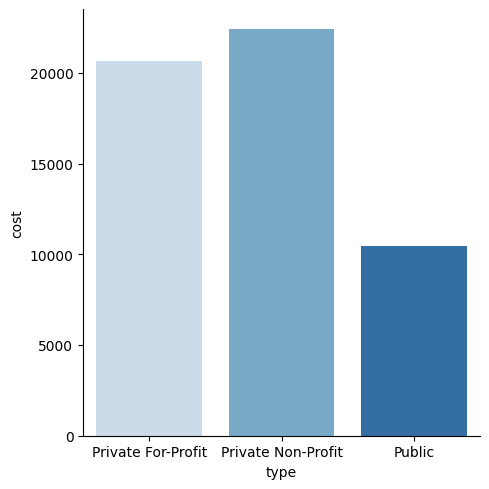

In [72]:
sns.catplot(kind='bar', data=type_vs_cost, x='type', y='cost', palette='Blues')
plt.show()

Public schools cost much less than private schools on average

How does student-faculty-ratio relate to cost?

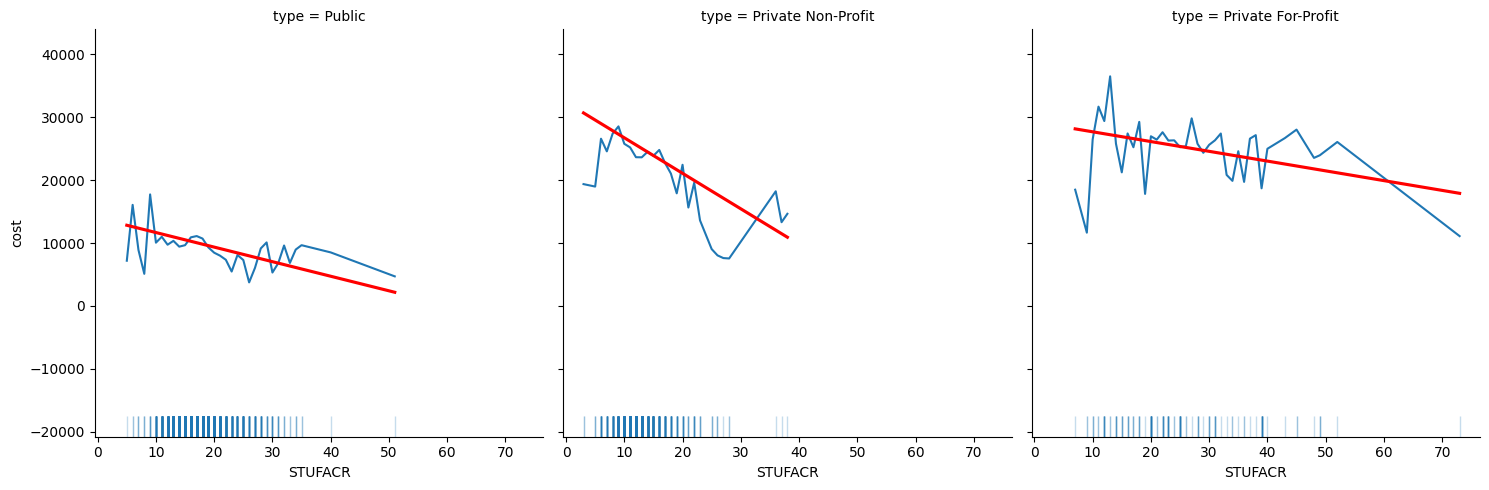

In [86]:
g = sns.relplot(kind='line', data=df, x='STUFACR', y='cost', estimator='median', errorbar=None, col='type')
g.map_dataframe(sns.rugplot, x='STUFACR',height=0.05, alpha=0.25)
g.map_dataframe(
    sns.regplot,
    x='STUFACR',
    y='cost',
    scatter=False,
    ci=None,
    color='red',
)
plt.show()

Map for colleges across the USA. Colored by type.

In [66]:
pip install geodatasets

In [67]:
# I Used AI extensively for this figure

# Drop missing coordinate rows
df = df.dropna(subset=['LATITUDE', 'LONGITUDE'])

# Generate the map
fig = px.scatter_geo(
    df,
    lat='LATITUDE',
    lon='LONGITUDE',
    hover_name='INSTNM',
    color='type',               # Plotly will now create a categorical legend
    scope='usa',
    title='Higher Education Institutions Across the United States',
    projection='albers usa',
    color_discrete_map={           # Optional: explicitly control the legend colors
        'Public': '#1f77b4',
        'Private Non-Profit': '#ff7f0e',
        'Private For-Profit': '#2ca02c'
    }
)

# Clean up the legend layout title (Optional)
fig.update_layout(legend_title_text='Institution Type')

fig.show()

For each type, there are many more institutions in the East than in the West.

Correlation and plot for undergraduate size and cost before and after removing outliers. Includes data cleaning. Only for schools with 1,000 or more undergraduates enrolled.

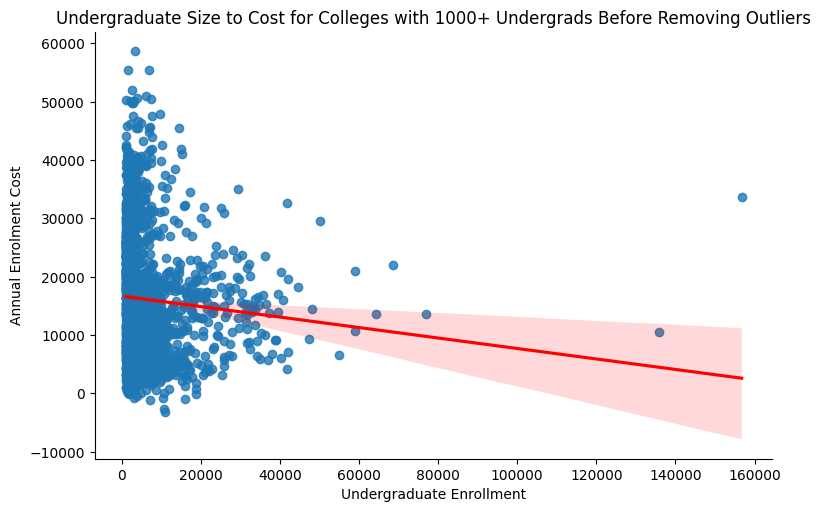

          UGDS      cost
UGDS  1.000000 -0.079099
cost -0.079099  1.000000
There is a very weak correlation between undergraduate size and cost


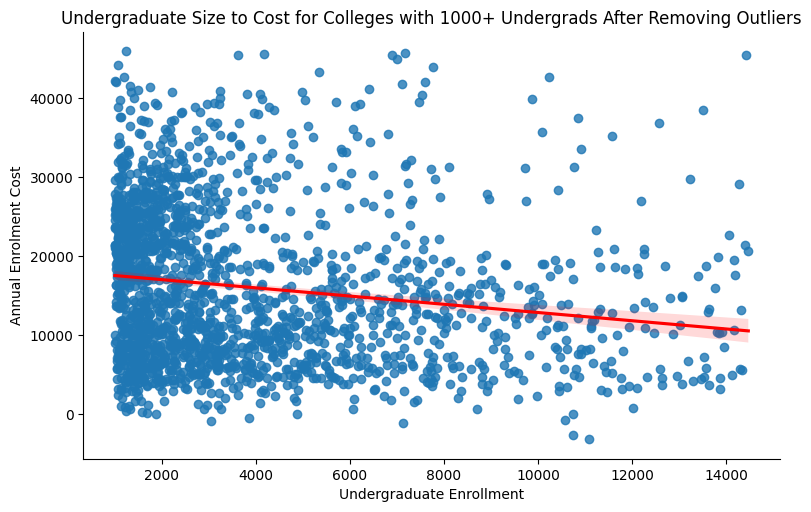

          UGDS      cost
UGDS  1.000000 -0.165801
cost -0.165801  1.000000
After removing outliers there is a higher, but still low correlation.


In [68]:
# Clean the columns
df = df.dropna(subset=['UGDS', 'cost'])
df['UGDS'] = pd.to_numeric(df['UGDS'], errors='coerce')
df['cost'] = pd.to_numeric(df['cost'], errors='coerce')

# Show only for schools with 1000 or more undergraduates
df = df[df['UGDS'] >= 1000]

# lmplot with outliers
sns.lmplot(x='UGDS', y='cost', data=df, line_kws={'color': 'red'}, height=5, aspect=1.6
           ).set(title="Undergraduate Size to Cost for Colleges with 1000+ Undergrads Before Removing Outliers").set_axis_labels('Undergraduate Enrollment', 'Annual Enrolment Cost'),
plt.show()

# Correlation before removing the outliers
print(df[['UGDS', 'cost']].corr())
print("There is a very weak correlation between undergraduate size and cost")

# Remove the outliers from UGDS and cost
uq1 = df['UGDS'].quantile(0.25)
uq3 = df['UGDS'].quantile(0.75)
uiqr = uq3 - uq1
ulower = uq1 - 1.5 * uiqr
uupper = uq3 + 1.5 * uiqr
df = df[df['UGDS'].between(ulower, uupper)]

cq1 = df['cost'].quantile(0.25)
cq3 = df['cost'].quantile(0.75)
ciqr = cq3 - cq1
clower = cq1 - 1.5 * ciqr
cupper = cq3 + 1.5 * ciqr
df = df[df['cost'].between(clower, cupper)]

# lmplot without outliers
sns.lmplot(x='UGDS', y='cost', data=df, line_kws={'color': 'red'}, height=5, aspect=1.6
           ).set(title="Undergraduate Size to Cost for Colleges with 1000+ Undergrads After Removing Outliers").set_axis_labels('Undergraduate Enrollment', 'Annual Enrolment Cost'),
plt.show()

# Correlation after removing outliers
print(df[['UGDS', 'cost']].corr())
print('After removing outliers there is a higher, but still low correlation.')
